# Market making su una borsa che segue: Avellaneda-Stoikov contro gli arbitraggisti

Il modello di Avellaneda & Stoikov (2008), replicato in [`avellaneda_stoikov.ipynb`](avellaneda_stoikov.ipynb), suppone che il market maker conosca il prezzo giusto e che chi esegue contro le sue quote sia **non informato**. Sui mercati reali il prezzo si forma su più borse insieme: per le crypto di solito guida Binance e le altre, per esempio Hyperliquid, seguono con un ritardo. Chi quota sulla borsa che segue vede il prezzo in ritardo, e gli **arbitraggisti** che vedono prima la borsa leader colpiscono le quote rimaste indietro.

È quello che abbiamo misurato nella gara [Perpetual Alpha](https://github.com/lancellottimatteo19/perpetual-alpha): l'82% degli scambi del bot che faceva market taking avveniva quando l'oracolo era già andato avanti rispetto al book, in media di 3,1 bp, e contro di lui il nostro market maker perdeva. Qui lo stesso fenomeno è riprodotto in un modello con due borse, senza l'oracolo della gara, per capire **quanto costa il ritardo** e **quali difese funzionano**.

## Il modello

**Prezzo efficiente** (borsa leader): un moto browniano più *eventi informativi*. Con intensità $\lambda_J$ arriva una notizia che sposta il prezzo di $J \sim N(0, s_J^2)$, e la borsa leader la incorpora gradualmente in $D$ secondi:
$$dP_t = \sigma\, dW_t + \text{eventi}.$$

**Market maker** sulla borsa che segue: vede $P_{t-L}$, cioè il prezzo con un ritardo di $L$ secondi, e quota con le formule di Avellaneda-Stoikov calcolate su quel prezzo:
$$r_t = P_{t-L} - q_t\, \gamma\, \sigma_{tot}^2 (T-t), \qquad \delta^a + \delta^b = \gamma\, \sigma_{tot}^2 (T-t) + \frac{2}{\gamma}\ln\left(1 + \frac{\gamma}{k}\right).$$

**Controparti**
* *Noise trader*, non informati: guardano il book della nostra borsa ed eseguono una quota a distanza $\delta$ dal mid con intensità $A e^{-k\delta}$, come nell'articolo.
* *Arbitraggisti*: vedono la borsa leader senza ritardo e comprano la nostra ask se $P_t - \text{ask} > c$, vendono al nostro bid se $\text{bid} - P_t > c$, dove $c$ è il loro costo (commissioni da taker sulle due borse).

**Difese**
* *Spread più largo*: si aggiungono alcuni bp per lato.
* *Guardia*: se il prezzo visto si è mosso di più di una soglia nell'ultimo secondo, si ritira per una pausa il lato che gli arbitraggisti colpirebbero (l'ask dopo un rialzo, il bid dopo un ribasso). È la versione semplificata della pausa dopo il bot usata in gara.

| Parametro | Valore |
|---|---|
| orizzonte, passo | 30 minuti, 100 ms |
| $\sigma$ | 0,5 bp per secondo$^{1/2}$ |
| eventi | uno ogni 30 s, $s_J = 10$ bp, incorporati in $D = 3$ s |
| noise trader | $A = 0{,}5$ al secondo per lato, $1/k = 1$ bp |
| costo degli arbitraggisti $c$ | 3 bp |
| $\gamma$, inventario massimo | 0,05, 10 unità |
| ordini | 1 unità di un titolo da 100 USD; 200 traiettorie |

Il codice è in [`two_venue_sim.py`](two_venue_sim.py), con i test in `tests/`. Tutte le varianti girano sulle **stesse traiettorie del prezzo**, così le differenze fra strategie non dipendono dal caso.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

import two_venue_sim as tv

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.float_format', '{:.2f}'.format)

market = tv.Market()                    # mezz'ora, passo di 100 ms, parametri del modulo
mm = tv.MarketMaker()                   # Avellaneda-Stoikov con gamma = 0.05 e 1 s di ritardo
N_PATHS = 200
price = tv.efficient_price(market, N_PATHS, np.random.default_rng(2026))

print(f"Semispread di Avellaneda-Stoikov: {tv.as_half_spread(market, mm, market.horizon) / tv.BP:.2f} bp all'inizio, "
      f"{tv.as_half_spread(market, mm, 0) / tv.BP:.2f} bp alla fine")
print(f"Volatilita' del prezzo efficiente: {np.sqrt(market.total_variance * 86400) / market.s0:.1%} al giorno")

Semispread di Avellaneda-Stoikov: 2.61 bp all'inizio, 1.00 bp alla fine
Volatilita' del prezzo efficiente: 5.6% al giorno


## 1. Il caso da manuale e il caso reale

In [2]:
def run(mk=market, m=mm, **kw):
    return tv.simulate(mk, m, n_paths=N_PATHS, seed=7, price=price, **kw)

risultati = {
    'Testo: nessun arbitraggista, ritardo 0': run(replace(market, arbitrage=False), replace(mm, latency=0.0)),
    'Con arbitraggisti, ritardo 1 s': run(trace=True),
}
pd.DataFrame({k: tv.summary(r) for k, r in risultati.items()}).T

,PnL,PnL sd,edge,inventario,esecuzioni noise,markout noise 10s (bp),esecuzioni arbitrage,markout arbitrage 10s (bp)
"Testo: nessun arbitraggista, ritardo 0",4.47,0.70,4.43,0.04,440.51,1.01,0.00,NaN
"Con arbitraggisti, ritardo 1 s",0.09,1.93,3.98,-3.89,476.17,1.91,68.11,-13.12


Senza arbitraggisti, con il prezzo visto senza ritardo, Avellaneda-Stoikov guadagna in media **4,47 USD in mezz'ora**. Ogni esecuzione con un noise trader vale circa +1 bp a 10 secondi: è lo spread catturato.

Con **1 secondo di ritardo** e gli arbitraggisti, il guadagno scende a **0,09 USD (−98%)**. Gli arbitraggisti sono solo 68 esecuzioni su circa 540 (13%), ma ciascuna costa in media **−13 bp** a 10 secondi. La perdita passa soprattutto per l'**inventario** (−3,89 USD): un arbitraggista ci vende proprio prima che il prezzo scenda ancora, e noi restiamo con la posizione sbagliata.

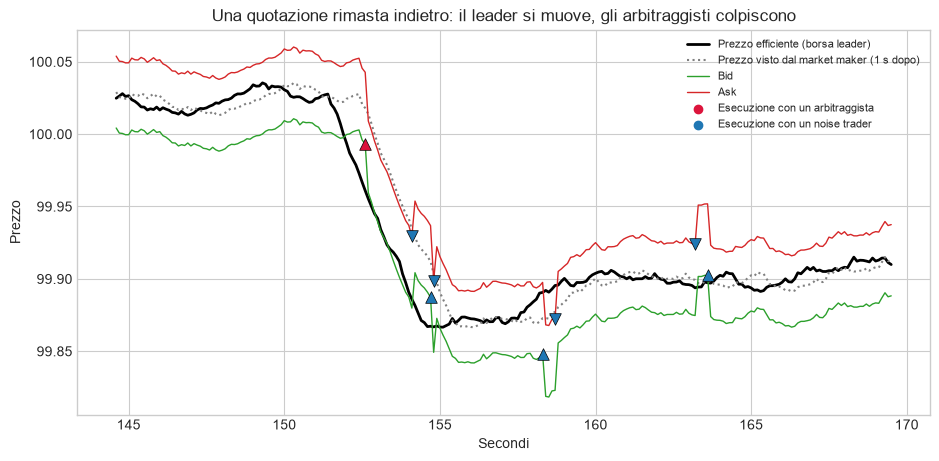

In [3]:
r = risultati['Con arbitraggisti, ritardo 1 s']
tr, dt = r['trace'], market.dt
arb_times = [f[0] for f in tr['fills'] if f[2] == 'arbitrage']
t0 = max(arb_times[0] - 8, 0)
t = np.arange(market.steps) * dt
w = (t >= t0) & (t <= t0 + 25)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t[w], r['price'][:-1, 0][w], color='black', lw=2, label='Prezzo efficiente (borsa leader)')
ax.plot(t[w], tr['seen'][w], color='gray', ls=':', label='Prezzo visto dal market maker (1 s dopo)')
ax.plot(t[w], tr['bid'][w], color='tab:green', lw=1, label='Bid')
ax.plot(t[w], tr['ask'][w], color='tab:red', lw=1, label='Ask')
for when, px, who, side in tr['fills']:
    if t0 <= when <= t0 + 25:
        ax.scatter(when, px, marker='^' if side > 0 else 'v', s=70, zorder=5,
                   color='crimson' if who == 'arbitrage' else 'tab:blue', edgecolor='black', linewidth=0.5)
ax.scatter([], [], marker='o', color='crimson', label='Esecuzione con un arbitraggista')
ax.scatter([], [], marker='o', color='tab:blue', label='Esecuzione con un noise trader')
ax.set_title('Una quotazione rimasta indietro: il leader si muove, gli arbitraggisti colpiscono')
ax.set_xlabel('Secondi'); ax.set_ylabel('Prezzo')
ax.legend(loc='best', fontsize=8)
plt.show()

Nel grafico la borsa leader scende di circa 15 bp in tre secondi. Il market maker vede il movimento con un secondo di ritardo, quindi per un attimo il suo bid resta sopra il prezzo vero: un arbitraggista ci vende lì (triangolo rosso), e il prezzo continua a scendere.

La tabella e il grafico che seguono mostrano la differenza fra le due controparti. Con i noise trader il guadagno cresce dopo l'esecuzione. Con gli arbitraggisti siamo già sotto di 3,75 bp al momento dell'esecuzione, e il movimento che segue porta la perdita a −13 bp: è la **selezione avversa**.

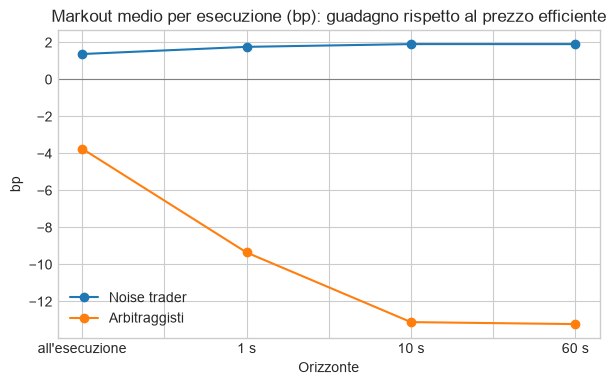

,all'esecuzione,1 s,10 s,60 s
Noise trader,1.37,1.76,1.91,1.91
Arbitraggisti,-3.75,-9.35,-13.12,-13.22


In [4]:
horizons = (1.0, 10.0, 60.0)
mk = run(markout_horizons=horizons)
rows = {}
for who, nome in [('noise', 'Noise trader'), ('arbitrage', 'Arbitraggisti')]:
    edge = mk['stats'][who]['edge'].sum() / mk['stats'][who]['fills'].sum() / tv.BP
    rows[nome] = {'all\'esecuzione': edge, **{f'{h:g} s': tv.markout_bp(mk, who, h) for h in horizons}}
markout = pd.DataFrame(rows).T
ax = markout.T.plot(marker='o', figsize=(7, 4))
ax.axhline(0, color='gray', lw=0.8)
ax.set_title('Markout medio per esecuzione (bp): guadagno rispetto al prezzo efficiente')
ax.set_xlabel('Orizzonte'); ax.set_ylabel('bp')
plt.show()
markout

## 2. Quanto costa il ritardo

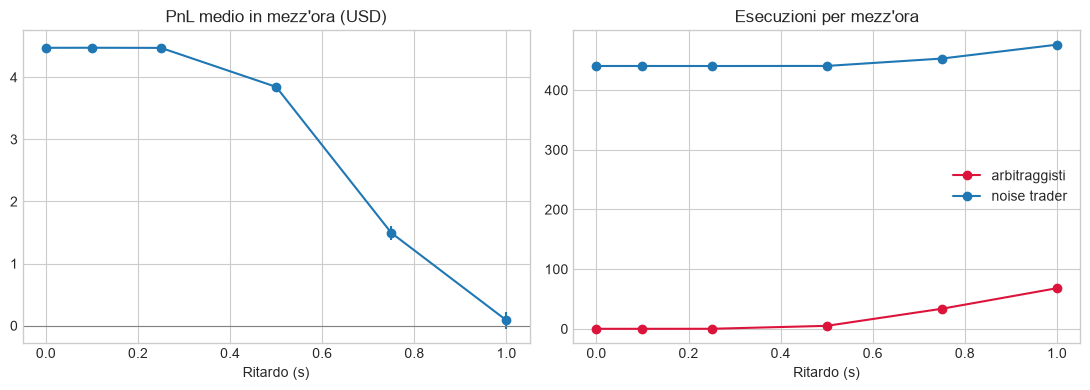

,PnL,PnL sd,edge,inventario,esecuzioni noise,markout noise 10s (bp),esecuzioni arbitrage,markout arbitrage 10s (bp)
ritardo (s),,,,,,,,
0.00,4.47,0.70,4.43,0.04,440.45,1.02,0.06,-1.50
0.10,4.47,0.70,4.43,0.04,440.46,1.02,0.06,-1.54
0.25,4.47,0.70,4.43,0.04,440.42,1.02,0.10,-8.65
0.50,3.84,0.86,4.34,-0.49,440.54,1.07,5.01,-17.36
0.75,1.49,1.62,3.99,-2.50,452.90,1.42,33.66,-14.53
1.00,0.09,1.93,3.98,-3.89,476.17,1.91,68.11,-13.12


In [5]:
latencies = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
lat = {L: tv.summary(run(m=replace(mm, latency=L))) for L in latencies}
lat = pd.DataFrame(lat).T
lat.index.name = 'ritardo (s)'

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(lat.index, lat['PnL'], yerr=lat['PnL sd'] / np.sqrt(N_PATHS), marker='o')
ax[0].axhline(0, color='gray', lw=0.8)
ax[0].set_title('PnL medio in mezz\'ora (USD)'); ax[0].set_xlabel('Ritardo (s)')
ax[1].plot(lat.index, lat['esecuzioni arbitrage'], marker='o', color='crimson', label='arbitraggisti')
ax[1].plot(lat.index, lat['esecuzioni noise'], marker='o', color='tab:blue', label='noise trader')
ax[1].set_title('Esecuzioni per mezz\'ora'); ax[1].set_xlabel('Ritardo (s)'); ax[1].legend()
plt.tight_layout(); plt.show()
lat

Fino a **250 ms** il ritardo non costa niente: il prezzo non fa in tempo a superare il nostro semispread più il costo degli arbitraggisti. Oltre i 500 ms la perdita cresce rapidamente, perché aumentano le esecuzioni con gli arbitraggisti.

Ci fermiamo a 1 secondo perché con ritardi più lunghi il modello diventa troppo ottimista. I noise trader guardano solo il nostro book, quindi eseguirebbero anche le quote vecchie a noi favorevoli. In una borsa reale quelle esecuzioni andrebbero a market maker concorrenti più veloci.

## 3. Le difese con 1 secondo di ritardo

**Allargare lo spread**

In [6]:
widen = {w: tv.summary(run(m=replace(mm, widen=w * tv.BP))) for w in [0.0, 0.5, 1.0, 2.0, 4.0]}
widen = pd.DataFrame(widen).T
widen.index.name = 'spread aggiunto per lato (bp)'
widen[['PnL', 'esecuzioni noise', 'esecuzioni arbitrage', 'markout arbitrage 10s (bp)']]

,PnL,esecuzioni noise,esecuzioni arbitrage,markout arbitrage 10s (bp)
spread aggiunto per lato (bp),,,,
0.00,0.09,476.17,68.11,-13.12
0.50,0.29,287.23,45.09,-13.94
1.00,0.15,174.25,30.77,-14.71
2.00,-0.14,63.77,14.66,-16.31
4.00,-0.15,7.95,3.37,-19.03


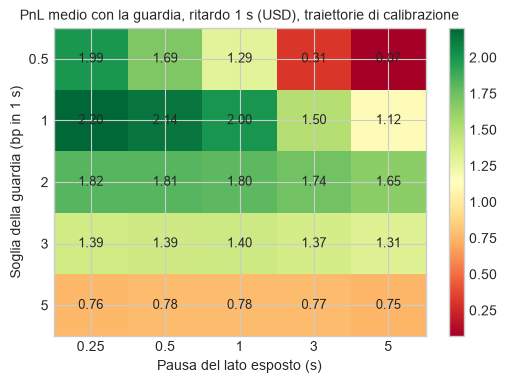

pausa (s),0.25,0.50,1.00,3.00,5.00
soglia (bp in 1 s),,,,,
0.50,1.99,1.69,1.29,0.31,0.07
1.00,2.20,2.14,2.00,1.50,1.12
2.00,1.82,1.81,1.80,1.74,1.65
3.00,1.39,1.39,1.40,1.37,1.31
5.00,0.76,0.78,0.78,0.77,0.75


In [7]:
# soglia e pausa si scelgono su traiettorie DIVERSE da quelle su cui si valuta il risultato finale
price_cal = tv.efficient_price(market, N_PATHS, np.random.default_rng(1))
thresholds, pauses = [0.5, 1.0, 2.0, 3.0, 5.0], [0.25, 0.5, 1.0, 3.0, 5.0]
grid = pd.DataFrame(index=pd.Index(thresholds, name='soglia (bp in 1 s)'), columns=pd.Index(pauses, name='pausa (s)'), dtype=float)
for th in thresholds:
    for pa in pauses:
        grid.loc[th, pa] = tv.simulate(market, replace(mm, guard_bps=th, guard_pause=pa), n_paths=N_PATHS, seed=11, price=price_cal)['pnl'].mean()

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values, cmap='RdYlGn', aspect='auto')
ax.set_xticks(range(len(pauses)), [f'{p:g}' for p in pauses]); ax.set_yticks(range(len(thresholds)), [f'{t:g}' for t in thresholds])
ax.set_xlabel('Pausa del lato esposto (s)'); ax.set_ylabel('Soglia della guardia (bp in 1 s)')
for i in range(len(thresholds)):
    for j in range(len(pauses)):
        ax.text(j, i, f'{grid.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('PnL medio con la guardia, ritardo 1 s (USD), traiettorie di calibrazione', fontsize=10)
plt.colorbar(im); plt.show()
grid

**Allargare lo spread aiuta poco.** Il PnL migliore, con +0,5 bp per lato, è 0,29 USD. Lo spread più largo allontana soprattutto i noise trader, che sono la fonte del guadagno. Gli arbitraggisti invece continuano a colpire nei movimenti grandi, e ogni loro esecuzione costa ancora di più: il markout scende da −13 a −19 bp.

**La guardia funziona meglio.** Ritira solo il lato esposto e solo quando serve, quindi toglie agli arbitraggisti le occasioni migliori senza perdere il flusso dei noise trader. Soglia e pausa sono scelte su un **insieme separato di traiettorie** e valutate nella tabella finale sulle traiettorie principali. Così il risultato non è gonfiato dalla scelta fatta sugli stessi dati.

## 4. Confronto finale

In [8]:
best_th, best_pa = np.unravel_index(np.nanargmax(grid.values), grid.shape)
guard = dict(guard_bps=thresholds[best_th], guard_pause=pauses[best_pa])
finale = {
    'Testo (nessun arbitraggista)': run(replace(market, arbitrage=False), replace(mm, latency=0.0)),
    'Ritardo 1 s': run(),
    'Ritardo 1 s + spread +1 bp': run(m=replace(mm, widen=1.0 * tv.BP)),
    f"Ritardo 1 s + guardia ({guard['guard_bps']:g} bp, {guard['guard_pause']:g} s)": run(m=replace(mm, **guard)),
    'Ritardo 250 ms': run(m=replace(mm, latency=0.25)),
    'Ritardo 250 ms + guardia': run(m=replace(mm, latency=0.25, **guard)),
}
pd.DataFrame({k: tv.summary(v) for k, v in finale.items()}).T

,PnL,PnL sd,edge,inventario,esecuzioni noise,markout noise 10s (bp),esecuzioni arbitrage,markout arbitrage 10s (bp)
Testo (nessun arbitraggista),4.47,0.70,4.43,0.04,440.51,1.01,0.00,NaN
Ritardo 1 s,0.09,1.93,3.98,-3.89,476.17,1.91,68.11,-13.12
Ritardo 1 s + spread +1 bp,0.15,1.68,2.84,-2.68,174.25,2.74,30.77,-14.71
"Ritardo 1 s + guardia (1 bp, 0.25 s)",2.10,1.22,4.11,-2.01,413.67,1.52,24.62,-16.89
Ritardo 250 ms,4.47,0.70,4.43,0.04,440.42,1.02,0.10,-8.65
Ritardo 250 ms + guardia,4.66,0.74,4.14,0.52,403.26,1.16,0.11,-2.92


## Conclusioni

| | PnL in mezz'ora (USD) |
|---|---:|
| Manuale, nessun arbitraggista | 4,47 |
| 1 s di ritardo | 0,09 |
| 1 s + spread +1 bp | 0,15 |
| 1 s + guardia (1 bp, 0,25 s) | 2,10 |
| 250 ms di ritardo | 4,47 |

1. **Il rischio principale di un market maker non è l'inventario in sé, ma con chi esegue.** Gli arbitraggisti sono pochi, ma ognuno costa circa sette volte quello che rende un'esecuzione con un noise trader (−13 bp contro +1,9 bp a 10 secondi).
2. **La velocità è la difesa più efficace.** Con 250 ms di ritardo, in questo modello, la selezione avversa sparisce. È il motivo per cui i market maker professionali investono in infrastruttura vicina alla borsa.
3. **Se non si può essere veloci, conta reagire nel modo giusto.** Con 1 secondo di ritardo la guardia recupera circa metà del guadagno perso. Allargare lo spread in modo simmetrico, invece, quasi non aiuta.

Sono le stesse conclusioni della gara: in Perpetual Alpha la difesa decisiva era la pausa dopo il bot, mentre ridurre la latenza da 2 s a 100 ms senza pausa riduceva la perdita senza eliminarla.

**Limiti del modello.** Gli arbitraggisti hanno liquidità illimitata e reagiscono subito. La coda del book e gli altri market maker non sono modellati. Gli ordini sono di una sola unità e i parametri non sono stimati su dati reali. Il passo successivo è calibrare ritardo ed eventi informativi sulle registrazioni di Binance e Hyperliquid, misurando di quanto la prima anticipa la seconda.

## Dove si colloca nella letteratura

Il modello non è un'idea nuova: mette insieme tre filoni noti in una forma semplice da simulare.

* **Selezione avversa e spread.** In Glosten e Milgrom (1985) lo spread esiste perché una parte del flusso è informata, e il market maker recupera dai non informati quello che perde con gli informati: è la divisione fra noise trader e arbitraggisti. Copeland e Galai (1983) descrivono una quota esposta come un'opzione gratuita offerta al mercato; una quota rimasta indietro è un'opzione già in the money. Kyle (1985) è il modello classico del trader informato.
* **Market making ottimale.** Avellaneda e Stoikov (2008) e Guéant, Lehalle e Fernandez-Tapia (2013) danno le quote ottimali con rischio di inventario. Cartea, Jaimungal e Ricci (2014) e Cartea, Jaimungal e Penalva (2015) aggiungono la selezione avversa e la tendenza del prezzo a continuare nella direzione degli ordini informati: è la versione rigorosa, con controllo ottimo, di quello che qui fa la guardia.
* **Latenza e quote vecchie.** È il filone più vicino. In Budish, Cramton e Shim (2015), quando un segnale pubblico muove il prezzo, i trader più veloci fanno a gara per colpire le quote rimaste indietro (*sniping*), e il costo ricade sui fornitori di liquidità; questo notebook ne è una versione semplificata in cui il market maker perde sempre la gara. Aquilina, Budish e O'Neill (2022) misurano queste gare sui dati della Borsa di Londra. Foucault, Kozhan e Tham (2017) mostrano sul mercato dei cambi che gli arbitraggi nati da informazione sono tossici per chi fornisce liquidità. Menkveld (2013) studia un market maker ad alta frequenza attivo su due borse.
* **Formazione del prezzo su più borse.** La *information share* di Hasbrouck (1995) misura quanta parte del prezzo si forma su ciascuna borsa, cioè chi è il leader; Makarov e Schoar (2020) studiano gli arbitraggi fra borse crypto.
* **Lo stesso fenomeno in DeFi.** Con il *loss-versus-rebalancing* di Milionis, Moallemi, Roughgarden e Zhang (2022), chi fornisce liquidità a un market maker automatico perde contro gli arbitraggisti che ne riallineano il prezzo a quello delle borse centralizzate: è il caso estremo di questo modello, in cui le quote non si aggiornano mai da sole.
* **Misure e difese.** Il markout per controparte è la misura standard della tossicità del flusso; il VPIN di Easley, López de Prado e O'Hara (2012) ne è una versione in tempo reale. Le difese reali somigliano alla guardia: il *last look* nel mercato dei cambi e gli *speed bump* asimmetrici di alcune borse, che ritardano i taker per dare ai market maker il tempo di aggiornare le quote.

Il contributo di questo notebook non è teorico: rende misurabile in una simulazione il meccanismo di Budish, Cramton e Shim, partendo da Avellaneda-Stoikov, e lo collega a quanto osservato nella gara Perpetual Alpha. Il passo che lo renderebbe originale è stimarne i parametri sui dati: di quanto Binance anticipa Hyperliquid e quanto è tossico il flusso dopo un suo movimento.

## Riferimenti

* Aquilina, M., Budish, E. e O'Neill, P. (2022). Quantifying the high-frequency trading "arms race". *Quarterly Journal of Economics*.
* Avellaneda, M. e Stoikov, S. (2008). High-frequency trading in a limit order book. *Quantitative Finance*.
* Budish, E., Cramton, P. e Shim, J. (2015). The high-frequency trading arms race: frequent batch auctions as a market design response. *Quarterly Journal of Economics*.
* Cartea, Á., Jaimungal, S. e Penalva, J. (2015). *Algorithmic and High-Frequency Trading*. Cambridge University Press.
* Cartea, Á., Jaimungal, S. e Ricci, J. (2014). Buy low, sell high: a high frequency trading perspective. *SIAM Journal on Financial Mathematics*.
* Copeland, T. e Galai, D. (1983). Information effects on the bid-ask spread. *Journal of Finance*.
* Easley, D., López de Prado, M. e O'Hara, M. (2012). Flow toxicity and liquidity in a high-frequency world. *Review of Financial Studies*.
* Foucault, T., Kozhan, R. e Tham, W. W. (2017). Toxic arbitrage. *Review of Financial Studies*.
* Glosten, L. e Milgrom, P. (1985). Bid, ask and transaction prices in a specialist market with heterogeneously informed traders. *Journal of Financial Economics*.
* Guéant, O., Lehalle, C.-A. e Fernandez-Tapia, J. (2013). Dealing with the inventory risk: a solution to the market making problem. *Mathematics and Financial Economics*.
* Hasbrouck, J. (1995). One security, many markets: determining the contributions to price discovery. *Journal of Finance*.
* Kyle, A. S. (1985). Continuous auctions and insider trading. *Econometrica*.
* Makarov, I. e Schoar, A. (2020). Trading and arbitrage in cryptocurrency markets. *Journal of Financial Economics*.
* Menkveld, A. J. (2013). High frequency trading and the new market makers. *Journal of Financial Markets*.
* Milionis, J., Moallemi, C. C., Roughgarden, T. e Zhang, A. L. (2022). Automated market making and loss-versus-rebalancing. Preprint arXiv.